# Project 01 · EEG Brain–Computer Interface: left vs right motor imagery

**Research question:** Can 8–30 Hz scalp EEG distinguish *imagined* left-fist from right-fist movements in people not seen during training?

**Data:** [PhysioNet EEG Motor Movement/Imagery](https://physionet.org/content/eegmmidb/1.0.0/), runs **4, 8, 12** only. In these runs `T1` is *imagined left fist* and `T2` is *imagined right fist*; `T0` (rest) is excluded. The original study measured 64 EEG channels at 160 Hz. These labels **must not** be generalized to runs 6/10/14, where T1/T2 have different meanings.

**Plan:** download → filter → epoch → inspect signals → train log-variance and CSP models → test each **held-out person** (leave-one-subject-out) and each held-out run within a person → save metrics and figures. This is an **offline exploratory decoder**, not an assistive device or a clinically validated BCI.

**Evaluation:** every participant is held out once (leave-one-subject-out), so each person's trials are predicted by a decoder that never saw them. No accuracy is asserted before running the notebook.

**Analysis plan, fixed on 28 October 2026 before any real data were analysed.** The first version of this notebook had not been run; these changes were made before running it.
- **Participants:** subjects 1–20 of 109 (the first version used 1–10).
- **Primary test (cross-subject):** CSP + logistic regression, leave-one-subject-out. One balanced accuracy per person; two-sided Wilcoxon signed-rank test against 0.5 across people, α = .05.
- **Secondary:** (a) the log-variance baseline; (b) CSP after Euclidean alignment (He & Wu, 2020), which re-centres each person's trial covariances using only that person's unlabelled trials; (c) within-subject decoding, training on two runs and testing on the third, which is the easier question most BCI studies report. Model differences use paired Wilcoxon tests and are secondary.
- **Per-person chance:** with about 45 trials per person, roughly 64% accuracy is needed before one person's result is distinguishable from chance (one-sided binomial, α = .05). Reported descriptively.
- **Changes from the first version:** a single random three-person test set is replaced by leave-one-subject-out over all participants; significance tests are added; Euclidean-aligned CSP and within-subject decoding are added; results no longer download automatically.

In [1]:
# In Google Colab, run once. Restart runtime only if Colab requests it.
%pip -q install "mne>=1.7,<2" "scikit-learn>=1.4,<2" "pandas>=2,<3" "matplotlib>=3.8,<4" "scipy>=1.11,<2"

In [2]:
from pathlib import Path
import json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from mne.datasets import eegbci
from mne.decoding import CSP
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from scipy import stats
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

SEED = 42
SUBJECTS = list(range(1, 21))  # 20 participants, fixed in the analysis plan
RUNS = (4, 8, 12)
FREQ_BAND = (8., 30.)  # mu and beta activity; pre-specified, no tuning on test set
EPOCH_WINDOW = (0.5, 3.5)  # seconds relative to motor-imagery onset
MONTAGE = 'colin27_1005' if 'colin27_1005' in mne.channels.get_builtin_montages() else 'standard_1005'  # renamed in MNE 1.13
OUT = Path('/content/neurotech_results/01_eeg_bci') if Path('/content').exists() else Path('neurotech_results/01_eeg_bci')
OUT.mkdir(parents=True, exist_ok=True)
mne.set_log_level('WARNING')
print('MNE', mne.__version__, '| Subjects:', SUBJECTS)

MNE 1.13.2 | Subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


In [3]:
# Load individual runs rather than concatenating files so labels and participant IDs stay explicit.
# Original EEG channel labels and spatial locations are standardized via MNE.
Xs, ys, groups, run_ids, record_rows = [], [], [], [], []
example_raw = None
for sid in SUBJECTS:
    sid_X, sid_y, sid_runs = [], [], []
    try:
        edf_files = eegbci.load_data(sid, list(RUNS), update_path=True, verbose=False)
    except Exception as exc:
        warnings.warn(f'Subject {sid} download failed: {exc}')
        continue
    for run_num, filename in zip(RUNS, edf_files):
        try:
            raw = mne.io.read_raw_edf(filename, preload=True, verbose=False)
            eegbci.standardize(raw)
            raw.set_montage(MONTAGE, on_missing='ignore', verbose=False)
            raw.pick_types(eeg=True, stim=False, exclude='bads')
            raw.set_eeg_reference('average', projection=False, verbose=False)
            raw.filter(*FREQ_BAND, fir_design='firwin', verbose=False)
            # MNE resolves T1 and T2 against annotation strings, not numerical codes.
            events, _ = mne.events_from_annotations(raw, event_id={'T1': 1, 'T2': 2}, verbose=False)
            epochs = mne.Epochs(raw, events, event_id={'left': 1, 'right': 2},
                                tmin=EPOCH_WINDOW[0], tmax=EPOCH_WINDOW[1],
                                baseline=None, preload=True, reject_by_annotation=True,
                                on_missing='ignore', verbose=False)
            if len(epochs) == 0:
                warnings.warn(f'No usable imagery epochs: subject {sid}, run {run_num}')
                continue
            arr = epochs.get_data(copy=True).astype(np.float64)
            labels = (epochs.events[:, -1] == 2).astype(int)  # 0=imagined left, 1=imagined right
            sid_X.append(arr)
            sid_y.append(labels)
            sid_runs.append(np.full(len(labels), run_num))
            record_rows.append({'subject':sid,'run':run_num,'n_epochs':len(arr),
                                'left':int((labels==0).sum()),'right':int((labels==1).sum())})
            if example_raw is None: example_raw = raw.copy()
        except Exception as exc:
            warnings.warn(f'Skipping subject {sid} run {run_num}: {exc}')
    if sid_X:
        XX, yy = np.concatenate(sid_X), np.concatenate(sid_y)
        if len(np.unique(yy)) < 2:
            warnings.warn(f'Subject {sid} has only one class; excluded')
            continue
        Xs.append(XX); ys.append(yy); groups.extend([sid]*len(yy)); run_ids.extend(np.concatenate(sid_runs).tolist())

if not Xs:
    raise RuntimeError('No data loaded. Check the PhysioNet connection, and retry.')
X = np.concatenate(Xs)
y = np.concatenate(ys)
groups = np.array(groups)
run_ids = np.array(run_ids)
assert len(X)==len(y)==len(groups)==len(run_ids)
assert len(set(groups))>=5, 'Use at least five successfully loaded subjects for meaningful held-out evaluation.'
assert set(np.unique(y))=={0,1}
print('Trials × channels × samples:', X.shape)
print('Subjects loaded:', sorted(np.unique(groups).tolist()))
print('Class counts:',{int(k): int(v) for k, v in zip(*np.unique(y,return_counts=True))})
pd.DataFrame(record_rows).to_csv(OUT/'run_inventory.csv',index=False)

Trials × channels × samples: (900, 64, 481)
Subjects loaded: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Class counts: {0: 455, 1: 445}


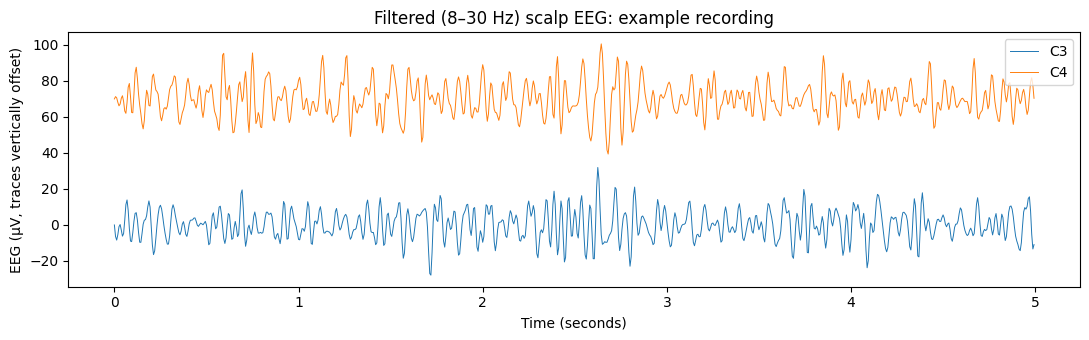

In [4]:
# Diagnostic visualization: continuous filtered EEG (C3 and C4 when present).
# Sensor locations and channel labels vary by dataset; verify channels before plotting.
channel_names = example_raw.ch_names
chosen = [ch for ch in ('C3','C4') if ch in channel_names]
if not chosen: chosen = channel_names[:2]
times = np.arange(int(5*example_raw.info['sfreq']))/example_raw.info['sfreq']
fig, ax = plt.subplots(figsize=(11,3.5))
for k, channel in enumerate(chosen):
    ax.plot(times, example_raw.get_data(picks=[channel],start=0,stop=len(times))[0]*1e6 + k*70,
            lw=.7,label=channel)
ax.set(xlabel='Time (seconds)',ylabel='EEG (µV, traces vertically offset)',
       title='Filtered (8–30 Hz) scalp EEG: example recording')
ax.legend(loc='upper right'); fig.tight_layout()
fig.savefig(OUT/'eeg_example_traces.png',dpi=170)
plt.show()

## Evaluation and leakage control

CSP learns spatial filters from labelled data, so it **must stay inside** the scikit-learn pipeline and be refitted for every held-out person; fitting it once to the complete dataset would leak test labels.

**Cross-subject:** each person is held out once, and both models are trained on everyone else. **Euclidean alignment** whitens each person's trials by that person's mean spatial covariance before CSP. It uses no labels, but for the held-out person it does use their unlabelled trials, so it assumes a short unlabelled calibration recording is available.

**Within-subject:** for each person, train on two runs and test on the third, rotating through all three runs, so no test trial comes from a run seen in training.

All settings are pre-specified; nothing is tuned on held-out results.

In [5]:
class LogChannelVariance(BaseEstimator, TransformerMixin):
    """A transparent baseline: one log-variance feature per EEG channel per epoch."""
    def fit(self, X, y=None): return self
    def transform(self, X):
        if X.ndim != 3: raise ValueError('Expected epochs × channels × samples')
        return np.log(np.maximum(np.var(X, axis=-1), 1e-20))

models = {
    'log_variance': Pipeline([
        ('features',LogChannelVariance()),('scale',StandardScaler()),
        ('logit',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED))]),
    'csp': Pipeline([
        ('csp',CSP(n_components=6, reg='ledoit_wolf', log=True, norm_trace=False)),
        ('scale',StandardScaler()),
        ('logit',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED))])
}


def euclidean_align(X, groups):
    """Re-centre each person's trials: X -> R^(-1/2) X, with R that person's mean spatial covariance (He & Wu, 2020).
    Uses no labels. The average reference removes one dimension, so R is inverted on its non-null eigenspace."""
    out = np.empty_like(X)
    for g in np.unique(groups):
        m = groups == g
        R = np.einsum('nct,ndt->cd', X[m], X[m]) / (m.sum() * X.shape[-1])
        w, V = np.linalg.eigh(R)
        inv_sqrt = np.where(w > w.max() * 1e-10, 1 / np.sqrt(np.clip(w, 1e-300, None)), 0.)
        out[m] = np.einsum('cd,ndt->nct', (V * inv_sqrt) @ V.T, X[m])
    return out


X_aligned = euclidean_align(X, groups)
cross_designs = {'log_variance': ('log_variance', X), 'csp': ('csp', X), 'csp_aligned': ('csp', X_aligned)}
subjects = np.unique(groups)
cross_rows = []
for design, (model_name, data) in cross_designs.items():
    for sid in subjects:
        test = groups == sid
        fitted = clone(models[model_name]).fit(data[~test], y[~test])
        pred = fitted.predict(data[test]); prob = fitted.predict_proba(data[test])[:, 1]
        cross_rows.append({'analysis': 'cross-subject', 'model': design, 'subject': sid, 'n_trials': int(test.sum()),
                           'n_correct': int((pred == y[test]).sum()), 'accuracy': accuracy_score(y[test], pred),
                           'balanced_accuracy': balanced_accuracy_score(y[test], pred), 'roc_auc': roc_auc_score(y[test], prob)})
cross_df = pd.DataFrame(cross_rows)
cross_df.to_csv(OUT/'cross_subject_by_person.csv', index=False)
display(cross_df.groupby('model')[['balanced_accuracy', 'roc_auc']].agg(['mean', 'std', 'min', 'max']).round(3))

balanced_accuracy                      roc_auc                \
                          mean    std    min    max    mean    std    min   
model                                                                       
csp                      0.552  0.116  0.366  0.844   0.615  0.189  0.306   
csp_aligned              0.645  0.155  0.396  0.934   0.677  0.190  0.366   
log_variance             0.569  0.104  0.375  0.819   0.621  0.171  0.265   

                     
                max  
model                
csp           0.947  
csp_aligned   0.972  
log_variance  0.949

In [6]:
# Within-subject reference: train on two runs, test on the third, for every person and run.
within_rows = []
for sid in subjects:
    m = groups == sid
    Xs_, ys_, rs_ = X[m], y[m], run_ids[m]
    for model_name in ('log_variance', 'csp'):
        pred = np.empty(len(ys_), int); prob = np.empty(len(ys_))
        for run in np.unique(rs_):
            te = rs_ == run
            if len(np.unique(ys_[~te])) < 2:
                raise RuntimeError(f'Subject {sid}: training runs contain one class')
            fitted = clone(models[model_name]).fit(Xs_[~te], ys_[~te])
            pred[te] = fitted.predict(Xs_[te]); prob[te] = fitted.predict_proba(Xs_[te])[:, 1]
        within_rows.append({'analysis': 'within-subject', 'model': model_name, 'subject': sid, 'n_trials': int(m.sum()),
                            'n_correct': int((pred == ys_).sum()), 'accuracy': accuracy_score(ys_, pred),
                            'balanced_accuracy': balanced_accuracy_score(ys_, pred), 'roc_auc': roc_auc_score(ys_, prob)})
within_df = pd.DataFrame(within_rows)
within_df.to_csv(OUT/'within_subject_by_person.csv', index=False)
display(within_df.groupby('model')[['balanced_accuracy', 'roc_auc']].agg(['mean', 'std', 'min', 'max']).round(3))

balanced_accuracy                      roc_auc                \
                          mean    std    min    max    mean    std    min   
model                                                                       
csp                      0.572  0.137  0.399  0.956   0.613  0.144  0.443   
log_variance             0.579  0.103  0.384  0.821   0.644  0.144  0.300   

                     
                max  
model                
csp           0.996  
log_variance  0.933

Primary test: cross-subject CSP vs 0.5 (two-sided Wilcoxon across people)


,analysis,model,n_people,mean_balanced_accuracy,ci95_low,ci95_high,wilcoxon_p_vs_0.5,people_above_chance_binomial,mean_roc_auc
0,cross-subject,log_variance,20.0,0.5689,0.5266,0.6147,0.0038,6.0,0.6206
1,cross-subject,csp,20.0,0.5516,0.5013,0.6042,0.0973,4.0,0.6147
2,cross-subject,csp_aligned,20.0,0.6448,0.5807,0.7125,0.0006,9.0,0.6775
3,within-subject,log_variance,20.0,0.5795,0.5373,0.6235,0.0032,5.0,0.6442
4,within-subject,csp,20.0,0.5721,0.5196,0.6347,0.0276,4.0,0.6129


Secondary comparisons (paired by person)


,comparison,mean_difference,wilcoxon_p,people_improved,n_people
0,cross-subject: CSP minus log-variance,-0.0174,0.3488,11,20
1,cross-subject: aligned CSP minus CSP,0.0933,0.0014,17,20
2,CSP: within-subject minus cross-subject,0.0205,0.6215,10,20


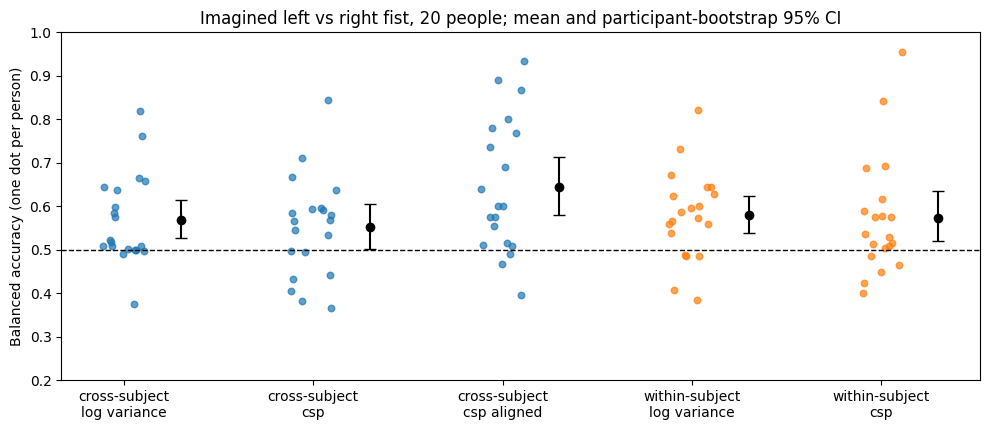

In [7]:
# Tests across people (the unit of inference), participant-bootstrap intervals and per-person binomial checks.
rng = np.random.default_rng(SEED)
results = pd.concat([cross_df, within_df], ignore_index=True)

def describe(g):
    x = g.balanced_accuracy.to_numpy()
    boot = rng.choice(x, (5000, len(x))).mean(1)
    per_person_p = [stats.binomtest(int(k), int(n), .5, alternative='greater').pvalue for k, n in zip(g.n_correct, g.n_trials)]
    return pd.Series({'n_people': len(x), 'mean_balanced_accuracy': x.mean(),
                      'ci95_low': np.quantile(boot, .025), 'ci95_high': np.quantile(boot, .975),
                      'wilcoxon_p_vs_0.5': stats.wilcoxon(x - .5).pvalue,
                      'people_above_chance_binomial': int(np.sum(np.array(per_person_p) < .05)),
                      'mean_roc_auc': g.roc_auc.mean()})

summary = results.groupby(['analysis', 'model'], sort=False).apply(describe, include_groups=False).reset_index()
summary.to_csv(OUT/'summary.csv', index=False)
print('Primary test: cross-subject CSP vs 0.5 (two-sided Wilcoxon across people)')
display(summary.round(4))

def paired(a, b, label):
    xa = a.set_index('subject').balanced_accuracy; xb = b.set_index('subject').balanced_accuracy.reindex(xa.index)
    d = xa - xb
    return {'comparison': label, 'mean_difference': d.mean(), 'wilcoxon_p': stats.wilcoxon(d).pvalue,
            'people_improved': int((d > 0).sum()), 'n_people': len(d)}

pick = lambda frame, model: frame[frame.model == model]
comparisons = pd.DataFrame([
    paired(pick(cross_df, 'csp'), pick(cross_df, 'log_variance'), 'cross-subject: CSP minus log-variance'),
    paired(pick(cross_df, 'csp_aligned'), pick(cross_df, 'csp'), 'cross-subject: aligned CSP minus CSP'),
    paired(pick(within_df, 'csp'), pick(cross_df, 'csp'), 'CSP: within-subject minus cross-subject')])
comparisons.to_csv(OUT/'paired_comparisons.csv', index=False)
print('Secondary comparisons (paired by person)')
display(comparisons.round(4))

fig, ax = plt.subplots(figsize=(10, 4.4))
order = [('cross-subject', 'log_variance'), ('cross-subject', 'csp'), ('cross-subject', 'csp_aligned'),
         ('within-subject', 'log_variance'), ('within-subject', 'csp')]
for i, (analysis, model) in enumerate(order):
    g = results[(results.analysis == analysis) & (results.model == model)]
    ax.scatter(np.full(len(g), i) + rng.uniform(-.12, .12, len(g)), g.balanced_accuracy, s=22, alpha=.7,
               color='tab:blue' if analysis == 'cross-subject' else 'tab:orange')
    row = summary[(summary.analysis == analysis) & (summary.model == model)].iloc[0]
    ax.errorbar(i + .3, row.mean_balanced_accuracy, yerr=[[row.mean_balanced_accuracy - row.ci95_low], [row.ci95_high - row.mean_balanced_accuracy]],
                fmt='o', color='black', capsize=4)
ax.axhline(.5, ls='--', color='black', lw=1)
ax.set_xticks(range(len(order)), [f'{a}\n{m.replace("_", " ")}' for a, m in order])
ax.set(ylabel='Balanced accuracy (one dot per person)', ylim=(.2, 1.0),
       title=f'Imagined left vs right fist, {len(subjects)} people; mean and participant-bootstrap 95% CI')
fig.tight_layout(); fig.savefig(OUT/'accuracy_by_person.png', dpi=170); plt.show()

In [8]:
# Store exact settings/versions to avoid claiming undocumented reproducibility.
config={'project':'01_left_vs_right_motor_imagery',
        'dataset':'PhysioNet EEG Motor Movement/Imagery v1.0.0',
        'dataset_url':'https://physionet.org/content/eegmmidb/1.0.0/',
        'subjects_requested':SUBJECTS,'subjects_loaded':sorted(np.unique(groups).tolist()),
        'runs':list(RUNS),'labels':{'0':'imagined left fist','1':'imagined right fist'},
        'epoch_window_seconds':EPOCH_WINDOW,'filter_hz':FREQ_BAND,
        'evaluation':{'cross_subject':'leave-one-subject-out','within_subject':'leave-one-run-out',
                      'alignment':'Euclidean alignment per person (He & Wu, 2020), label-free'},
        'primary_test':'cross-subject CSP balanced accuracy vs 0.5, two-sided Wilcoxon across people',
        'analysis_plan_fixed':'2026-10-28, before real data were analysed','seed':SEED,
        'python':platform.python_version(),'mne':mne.__version__,
        'sklearn':__import__('sklearn').__version__}
(OUT/'settings.json').write_text(json.dumps(config,indent=2,default=str))
print('Files:',*[p.name for p in sorted(OUT.iterdir())],sep='\n - ')
# Google Drive optional (if you want permanent storage):
# from google.colab import drive
# drive.mount('/content/drive')
# import shutil
# shutil.copytree(OUT,'/content/drive/MyDrive/cognitive_neurotech/01_eeg_bci',dirs_exist_ok=True)

Files:
 - accuracy_by_person.png
 - cross_subject_by_person.csv
 - eeg_example_traces.png
 - paired_comparisons.csv
 - run_inventory.csv
 - settings.json
 - summary.csv
 - within_subject_by_person.csv


## Exploratory analyses (added after the results above were seen)

These analyses were added on 28 October 2026, after the primary and secondary results above had been seen and reviewed. They are not part of the analysis plan, they are reported descriptively, and none of them replaces the primary test.

1. **Where is the decodable signal?** The target appears on the left or right of the screen, so the label could be carried by lateralized visual attention (posterior alpha) or by eye movements (frontal channels) as well as by motor imagery. Cross-subject CSP, with and without Euclidean alignment, is repeated on three channel groups defined by electrode row: sensorimotor (FC, C and CP rows, 21 channels), posterior (P, PO, O and Iz, 18) and frontal (Fp, AF and F rows, 17). Each group is re-referenced to its own average, so activity outside the group cannot enter through the average reference. Decoding from sensorimotor channels does not by itself rule out the confound, and decoding from posterior channels does not by itself establish it; the comparison is a first check.
2. **Alignment with a separate calibration recording.** Above, each held-out person's alignment used all of their trials, including the ones being classified. Here it uses only their first imagery run (run 4, 15 trials, labels unused), and the decoder is scored on runs 8 and 12. Unaligned and batch-aligned CSP are scored on the same 30 trials for comparison. With 30 trials, about 67% correct is needed before one person's result differs from chance (one-sided binomial, α = .05).

In [9]:
# Exploratory 1: cross-subject CSP on channel groups defined by electrode row (fixed before running this cell).
names = [ch.upper() for ch in example_raw.ch_names]
regions = {
    'sensorimotor': [i for i, n in enumerate(names) if n.startswith(('FC', 'C'))],
    'posterior': [i for i, n in enumerate(names) if n.startswith(('P', 'O', 'I'))],
    'frontal': [i for i, n in enumerate(names) if n.startswith(('FP', 'AF', 'F')) and not n.startswith(('FC', 'FT'))]}
assert {k: len(v) for k, v in regions.items()} == {'sensorimotor': 21, 'posterior': 18, 'frontal': 17}, {k: len(v) for k, v in regions.items()}
for region, idx in regions.items():
    print(f'{region:12s}', ' '.join(example_raw.ch_names[i] for i in idx))

explore_rows = []
for region, idx in regions.items():
    Xr = X[:, idx, :]
    Xr = Xr - Xr.mean(axis=1, keepdims=True)  # re-reference to the group's own average
    for design, data in (('csp', Xr), ('csp_aligned', euclidean_align(Xr, groups))):
        for sid in subjects:
            test = groups == sid
            fitted = clone(models['csp']).fit(data[~test], y[~test])
            pred = fitted.predict(data[test]); prob = fitted.predict_proba(data[test])[:, 1]
            explore_rows.append({'analysis': f'channels: {region}', 'model': design, 'subject': sid, 'n_trials': int(test.sum()),
                                 'n_correct': int((pred == y[test]).sum()), 'accuracy': accuracy_score(y[test], pred),
                                 'balanced_accuracy': balanced_accuracy_score(y[test], pred), 'roc_auc': roc_auc_score(y[test], prob)})

sensorimotor FC5 FC3 FC1 FCz FC2 FC4 FC6 C5 C3 C1 Cz C2 C4 C6 CP5 CP3 CP1 CPz CP2 CP4 CP6
posterior    P7 P5 P3 P1 Pz P2 P4 P6 P8 PO7 PO3 POz PO4 PO8 O1 Oz O2 Iz
frontal      Fp1 Fpz Fp2 AF7 AF3 AFz AF4 AF8 F7 F5 F3 F1 Fz F2 F4 F6 F8


Exploratory: tests across people (descriptive; not part of the analysis plan)


,analysis,model,n_people,mean_balanced_accuracy,ci95_low,ci95_high,wilcoxon_p_vs_0.5,people_above_chance_binomial,mean_roc_auc
0,channels: sensorimotor,csp,20.0,0.5726,0.5228,0.6294,0.0263,4.0,0.6334
1,channels: sensorimotor,csp_aligned,20.0,0.6426,0.5804,0.7072,0.0002,9.0,0.6842
2,channels: posterior,csp,20.0,0.5353,0.5111,0.5641,0.0123,1.0,0.5644
3,channels: posterior,csp_aligned,20.0,0.5716,0.5312,0.6099,0.0042,5.0,0.5810
4,channels: frontal,csp,20.0,0.4966,0.4713,0.5179,0.6377,0.0,0.5102
5,channels: frontal,csp_aligned,20.0,0.5450,0.5120,0.5784,0.0216,2.0,0.5532
6,held-out runs 8 and 12 (alignment from run 4 o...,csp,20.0,0.5660,0.5127,0.6215,0.0399,3.0,0.6375
7,held-out runs 8 and 12 (alignment from run 4 o...,csp_aligned_batch,20.0,0.6511,0.5901,0.7158,0.0007,8.0,0.6872
8,held-out runs 8 and 12 (alignment from run 4 o...,csp_aligned_calibration_run,20.0,0.6475,0.5862,0.7114,0.0005,8.0,0.6871


,comparison,mean_difference,wilcoxon_p,people_improved,n_people
0,CSP: sensorimotor minus posterior channels,0.0373,0.2548,11,20
1,aligned CSP: sensorimotor minus posterior chan...,0.0710,0.0050,16,20
2,runs 8 and 12: calibration-run alignment minus...,0.0815,0.0055,14,20
3,runs 8 and 12: calibration-run minus batch ali...,-0.0036,0.9773,8,20


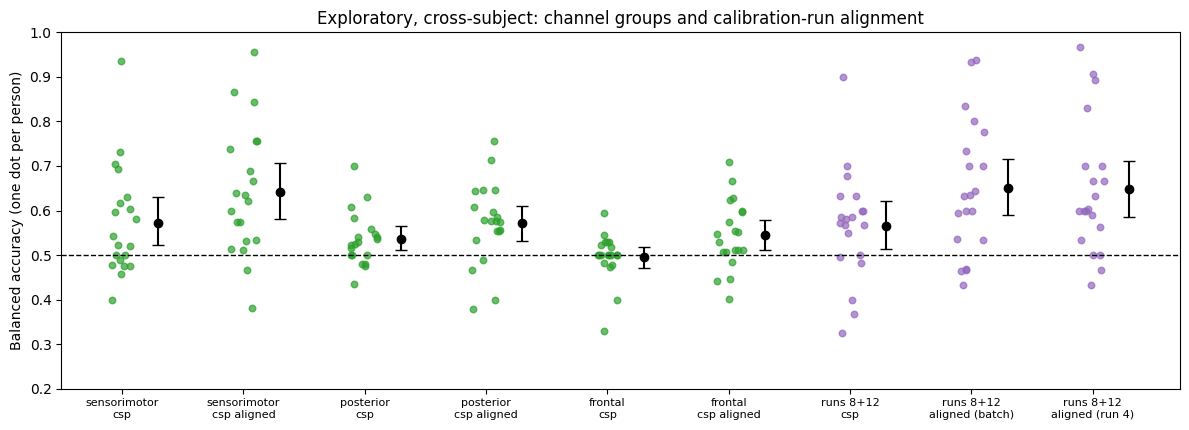

Exploratory results written to /content/neurotech_results/01_eeg_bci


In [10]:
# Exploratory 2: Euclidean alignment computed from a separate calibration run, scored on the remaining runs.
CALIBRATION_RUN = 4
CAL = f'held-out runs 8 and 12 (alignment from run {CALIBRATION_RUN} only)'

def align_to(X_target, X_reference):
    """Whiten X_target by R^(-1/2), R the mean spatial covariance of X_reference (non-null eigenspace, as above)."""
    R = np.einsum('nct,ndt->cd', X_reference, X_reference) / (len(X_reference) * X_reference.shape[-1])
    w, V = np.linalg.eigh(R)
    inv_sqrt = np.where(w > w.max() * 1e-10, 1 / np.sqrt(np.clip(w, 1e-300, None)), 0.)
    return np.einsum('cd,ndt->nct', (V * inv_sqrt) @ V.T, X_target)

for sid in subjects:
    person = groups == sid
    evaluate = person & (run_ids != CALIBRATION_RUN)
    calibration = person & (run_ids == CALIBRATION_RUN)
    plain = clone(models['csp']).fit(X[~person], y[~person])
    aligned = clone(models['csp']).fit(X_aligned[~person], y[~person])  # training people aligned with all their trials, as above
    for design, fitted, test_X in (('csp', plain, X[evaluate]),
                                   ('csp_aligned_batch', aligned, X_aligned[evaluate]),
                                   ('csp_aligned_calibration_run', aligned, align_to(X[evaluate], X[calibration]))):
        pred = fitted.predict(test_X); prob = fitted.predict_proba(test_X)[:, 1]
        explore_rows.append({'analysis': CAL, 'model': design, 'subject': sid, 'n_trials': int(evaluate.sum()),
                             'n_correct': int((pred == y[evaluate]).sum()), 'accuracy': accuracy_score(y[evaluate], pred),
                             'balanced_accuracy': balanced_accuracy_score(y[evaluate], pred), 'roc_auc': roc_auc_score(y[evaluate], prob)})

explore = pd.DataFrame(explore_rows)
explore.to_csv(OUT/'exploratory_by_person.csv', index=False)
explore_summary = explore.groupby(['analysis', 'model'], sort=False).apply(describe, include_groups=False).reset_index()
explore_summary.to_csv(OUT/'exploratory_summary.csv', index=False)
print('Exploratory: tests across people (descriptive; not part of the analysis plan)')
display(explore_summary.round(4))

pick2 = lambda analysis, model: explore[(explore.analysis == analysis) & (explore.model == model)]
explore_pairs = pd.DataFrame([
    paired(pick2('channels: sensorimotor', 'csp'), pick2('channels: posterior', 'csp'), 'CSP: sensorimotor minus posterior channels'),
    paired(pick2('channels: sensorimotor', 'csp_aligned'), pick2('channels: posterior', 'csp_aligned'), 'aligned CSP: sensorimotor minus posterior channels'),
    paired(pick2(CAL, 'csp_aligned_calibration_run'), pick2(CAL, 'csp'), 'runs 8 and 12: calibration-run alignment minus none'),
    paired(pick2(CAL, 'csp_aligned_calibration_run'), pick2(CAL, 'csp_aligned_batch'), 'runs 8 and 12: calibration-run minus batch alignment')])
explore_pairs.to_csv(OUT/'exploratory_paired_comparisons.csv', index=False)
display(explore_pairs.round(4))

fig, ax = plt.subplots(figsize=(12, 4.4))
order = [(f'channels: {r}', m) for r in regions for m in ('csp', 'csp_aligned')] + [(CAL, m) for m in ('csp', 'csp_aligned_batch', 'csp_aligned_calibration_run')]
labels = [f'{r}\n{m.replace("_", " ")}' for r in regions for m in ('csp', 'csp_aligned')] + ['runs 8+12\ncsp', 'runs 8+12\naligned (batch)', 'runs 8+12\naligned (run 4)']
for i, (analysis, model) in enumerate(order):
    g = explore[(explore.analysis == analysis) & (explore.model == model)]
    ax.scatter(np.full(len(g), i) + rng.uniform(-.12, .12, len(g)), g.balanced_accuracy, s=22, alpha=.7,
               color='tab:green' if analysis.startswith('channels') else 'tab:purple')
    row = explore_summary[(explore_summary.analysis == analysis) & (explore_summary.model == model)].iloc[0]
    ax.errorbar(i + .3, row.mean_balanced_accuracy, yerr=[[row.mean_balanced_accuracy - row.ci95_low], [row.ci95_high - row.mean_balanced_accuracy]],
                fmt='o', color='black', capsize=4)
ax.axhline(.5, ls='--', color='black', lw=1)
ax.set_xticks(range(len(order)), labels, fontsize=8)
ax.set(ylabel='Balanced accuracy (one dot per person)', ylim=(.2, 1.0),
       title='Exploratory, cross-subject: channel groups and calibration-run alignment')
fig.tight_layout(); fig.savefig(OUT/'exploratory_by_person.png', dpi=170); plt.show()

(OUT/'exploratory_settings.json').write_text(json.dumps({
    'added': '2026-10-28, after the planned results had been seen; descriptive, not part of the analysis plan',
    'channel_groups': {r: [example_raw.ch_names[i] for i in idx] for r, idx in regions.items()},
    'channel_group_reference': "each group's own average",
    'calibration_run': CALIBRATION_RUN, 'evaluation_runs': [8, 12]}, indent=2))
print('Exploratory results written to', OUT)

## Interpretation checklist

1. **What is being predicted?** The cue specifying imagined left/right movement; the model does not directly read an intention or operate a real-time device.
2. **What is the unit of generalization?** Unseen people for the cross-subject analysis; unseen runs from the same person for the within-subject analysis. These are different questions, and within-subject accuracy is usually higher.
3. **How should 50% be interpreted?** Near chance for balanced left/right labels; confirm balanced accuracy and class counts.
4. **Are we above chance?** Use the test across people, not pooled trials: trials from one person are not independent. Per-person binomial tests describe who is above chance; they are not the group test.
5. **What could be confounded?** Cue-locked stimulus processing, individual differences, run effects, artifacts and different preprocessing decisions.
6. **What to report publicly?** Number of subjects, trials, preprocessing, split procedure, chance level, balanced accuracy, ROC AUC, variance and failures. Never invent model performance.

**Recommended extensions:** alpha/mu vs beta ablations; temporal generalization; calibration and test–retest; more participants. Avoid claiming device readiness.

**References:** Schalk G. et al. (2004). BCI2000: a general-purpose brain-computer interface system. *IEEE Transactions on Biomedical Engineering*, 51(6), 1034–1043. Goldberger A. L. et al. (2000). PhysioBank, PhysioToolkit, and PhysioNet. *Circulation*, 101(23), e215–e220. He H. & Wu D. (2020). Transfer learning for brain-computer interfaces: a Euclidean space data alignment approach. *IEEE Transactions on Biomedical Engineering*, 67(2), 399–410.

### Results archive

The archive holds only generated figures, CSV files and settings, not the raw EEG data. Download it from the Files panel on the left.

In [11]:
import shutil
results_zip = shutil.make_archive(str(OUT), 'zip', root_dir=str(OUT))
print('Result archive (download from the Files panel):', results_zip)

Result archive (download from the Files panel): /content/neurotech_results/01_eeg_bci.zip
